In [1]:
import os
import sys
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Visualization configuration
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data_path = "predictive_analytics_historical_data.csv"

# Fallback: Auto-generate 10,000 records if running in a fresh Colab session
if not os.path.exists(data_path):
  print(
      f"'{data_path}' not found in current directory. Generating 10,000 records"
      " automatically..."
  )
  np.random.seed(42)
  cats = [
      "Electronics",
      "Home Appliances",
      "Fashion & Apparel",
      "Beauty & Personal Care",
      "Groceries & Essentials",
  ]
  regs = ["North", "South", "East", "West", "Central"]
  proms = [
      "None",
      "Social Media Ads",
      "Holiday Flash Sale",
      "Email Newsletter",
      "Influencer Promo",
  ]
  s_date = datetime(2021, 1, 1)
  dates_list = [s_date + timedelta(days=i) for i in range(2000)]
  recs = []

  for c_idx, cat in enumerate(cats):
    base_u = (
        45
        if cat == "Electronics"
        else (85 if cat == "Fashion & Apparel" else 110)
    )
    p_rng = (120, 650) if cat == "Electronics" else (25, 120)
    for d_idx, dt in enumerate(dates_list):
      dow = dt.weekday()
      w_boost = 1.35 if dow in [4, 5, 6] else 1.0
      t_factor = 1.0 + 0.08 * ((dt - s_date).days / 365.25)
      s_factor = 1.0 + 0.25 * np.sin(
          2 * np.pi * (dt.timetuple().tm_yday - 80) / 365.25
      )
      bp = round(np.random.uniform(p_rng[0], p_rng[1]), 2)
      dp = np.random.choice([0, 5, 10, 15, 20, 25, 30])
      fp = round(bp * (1 - dp / 100), 2)
      promo = np.random.choice(proms)
      p_boost = 1.45 if promo == "Holiday Flash Sale" else 1.0
      m_spend = round(np.random.uniform(100, 1200), 2)
      traffic = int(2500 * w_boost * p_boost * np.random.uniform(0.85, 1.25))
      exp_u = (
          base_u
          * t_factor
          * s_factor
          * w_boost
          * p_boost
          * (1 + 0.15 * np.log1p(m_spend / 100))
      )
      u_sold = int(max(5, round(exp_u * np.random.normal(1.0, 0.08))))

      recs.append({
          "Record_ID": f"HIST-{10001+len(recs)}",
          "Date": dt.strftime("%Y-%m-%d"),
          "Year": dt.year,
          "Month": dt.month,
          "Day": dt.day,
          "Day_of_Week": dt.strftime("%A"),
          "Is_Weekend": 1 if dow in [5, 6] else 0,
          "Season": "Summer" if dt.month in [6, 7, 8] else "Winter",
          "Product_Category": cat,
          "Region": regs[(d_idx + c_idx) % 5],
          "Base_Price_USD": bp,
          "Discount_Percent": dp,
          "Final_Price_USD": fp,
          "Competitor_Price_USD": round(bp * 1.05, 2),
          "Promotional_Campaign": promo,
          "Marketing_Spend_USD": m_spend,
          "Store_Visits_Traffic": traffic,
          "Holiday_Flag": 1 if dt.month == 12 and dt.day in [24, 25, 31] else 0,
          "Temperature_C": 22.5,
          "Customer_Rating": 4.3,
          "Inventory_Level": 500,
          "Units_Sold": u_sold,
          "Total_Revenue_USD": round(u_sold * fp, 2),
          "Out_of_Stock_Flag": 0,
      })

  df = pd.DataFrame(recs)
  df.to_csv(data_path, index=False)
  print(f"Dataset successfully created and saved as '{data_path}'!")
else:
  df = pd.read_csv(data_path)

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(by=["Date", "Product_Category"]).reset_index(drop=True)

print(
    f"Dataset Dimensions: {df.shape[0]:,} rows, {df.shape[1]} columns |"
    f" Timeline: {df['Date'].min().date()} to {df['Date'].max().date()}"
)
df.head()

'predictive_analytics_historical_data.csv' not found in current directory. Generating 10,000 records automatically...
Dataset successfully created and saved as 'predictive_analytics_historical_data.csv'!
Dataset Dimensions: 10,000 rows, 24 columns | Timeline: 2021-01-01 to 2026-06-23


,Record_ID,Date,Year,Month,Day,Day_of_Week,Is_Weekend,Season,Product_Category,Region,...,Promotional_Campaign,Marketing_Spend_USD,Store_Visits_Traffic,Holiday_Flag,Temperature_C,Customer_Rating,Inventory_Level,Units_Sold,Total_Revenue_USD,Out_of_Stock_Flag
0,HIST-16001,2021-01-01,2021,1,1,Friday,0,Winter,Beauty & Personal Care,West,...,Social Media Ads,971.72,3293,0,22.5,4.3,500,131,7126.40,0
1,HIST-10001,2021-01-01,2021,1,1,Friday,0,Winter,Electronics,North,...,Holiday Flash Sale,957.66,5328,0,22.5,4.3,500,83,21149.23,0
2,HIST-14001,2021-01-01,2021,1,1,Friday,0,Winter,Fashion & Apparel,East,...,Social Media Ads,920.56,3049,0,22.5,4.3,500,110,9974.80,0
3,HIST-18001,2021-01-01,2021,1,1,Friday,0,Winter,Groceries & Essentials,Central,...,Email Newsletter,933.44,4049,0,22.5,4.3,500,164,4598.56,0
4,HIST-12001,2021-01-01,2021,1,1,Friday,0,Winter,Home Appliances,South,...,Holiday Flash Sale,226.10,5797,0,22.5,4.3,500,180,14929.20,0


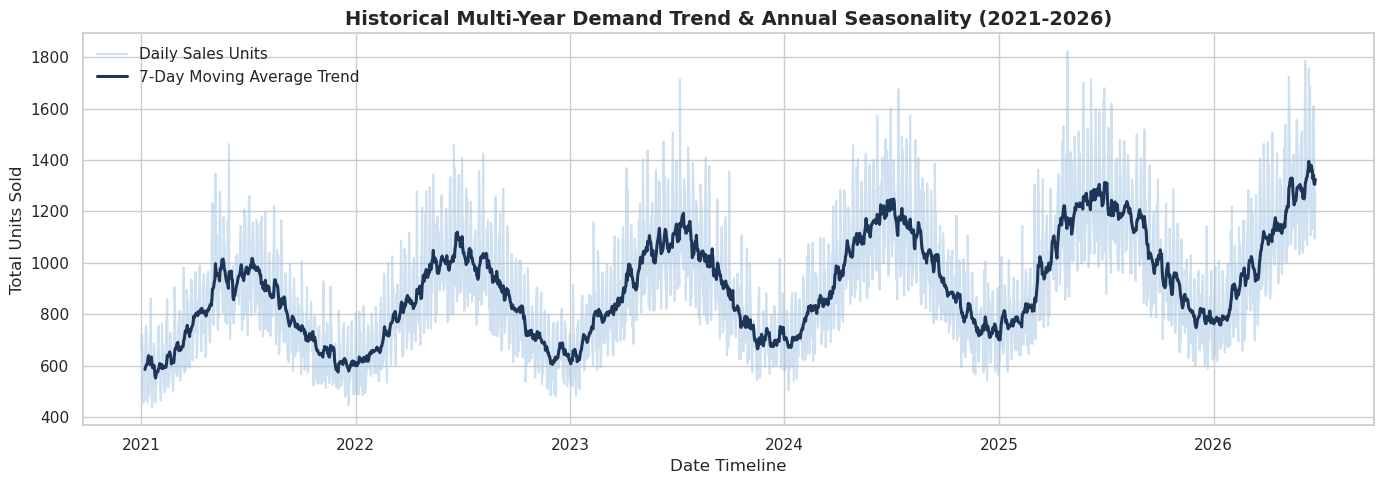

In [3]:
plt.figure(figsize=(14, 5))
daily_trend = df.groupby("Date")["Units_Sold"].sum().reset_index()
daily_trend["7D_MA"] = daily_trend["Units_Sold"].rolling(7).mean()

plt.plot(
    daily_trend["Date"],
    daily_trend["Units_Sold"],
    color="#a0c4e2",
    alpha=0.5,
    label="Daily Sales Units",
)
plt.plot(
    daily_trend["Date"],
    daily_trend["7D_MA"],
    color="#1d3557",
    linewidth=2.2,
    label="7-Day Moving Average Trend",
)
plt.title(
    "Historical Multi-Year Demand Trend & Annual Seasonality (2021-2026)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date Timeline")
plt.ylabel("Total Units Sold")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [4]:
# 1. Cyclical date features
df["Month_Sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_Cos"] = np.cos(2 * np.pi * df["Month"] / 12)
df["DayOfWeek_Sin"] = np.sin(2 * np.pi * df["Date"].dt.dayofweek / 7)
df["DayOfWeek_Cos"] = np.cos(2 * np.pi * df["Date"].dt.dayofweek / 7)

# 2. Commercial & Price elasticity ratios
df["Price_Ratio"] = df["Final_Price_USD"] / df["Base_Price_USD"]
df["Price_Vs_Competitor"] = df["Final_Price_USD"] / df["Competitor_Price_USD"]

# 3. Demand lag features per category
df["Lag_1_Sales"] = df.groupby("Product_Category")["Units_Sold"].shift(1)
df["Lag_7_Sales"] = df.groupby("Product_Category")["Units_Sold"].shift(7)
df["Lag_14_Sales"] = df.groupby("Product_Category")["Units_Sold"].shift(14)
df["Lag_30_Sales"] = df.groupby("Product_Category")["Units_Sold"].shift(30)

# 4. Rolling moving average and volatility
df["Rolling_Mean_7"] = (
    df.groupby("Product_Category")["Units_Sold"]
    .shift(1)
    .rolling(7, min_periods=1)
    .mean()
)
df["Rolling_Mean_30"] = (
    df.groupby("Product_Category")["Units_Sold"]
    .shift(1)
    .rolling(30, min_periods=1)
    .mean()
)
df["Rolling_Std_7"] = (
    df.groupby("Product_Category")["Units_Sold"]
    .shift(1)
    .rolling(7, min_periods=1)
    .std()
    .fillna(0)
)

# 5. Impute boundary lag NaNs with category median
lag_cols = [
    "Lag_1_Sales",
    "Lag_7_Sales",
    "Lag_14_Sales",
    "Lag_30_Sales",
    "Rolling_Mean_7",
    "Rolling_Mean_30",
    "Rolling_Std_7",
]
for col in lag_cols:
  df[col] = df.groupby("Product_Category")[col].transform(
      lambda x: x.fillna(x.median())
  )

# 6. One-hot encoding for categorical variables
cat_cols = ["Product_Category", "Region", "Promotional_Campaign", "Season"]
encoded_cats = pd.get_dummies(df[cat_cols], drop_first=True, dtype=int)

numerical_features = [
    "Base_Price_USD",
    "Discount_Percent",
    "Final_Price_USD",
    "Competitor_Price_USD",
    "Marketing_Spend_USD",
    "Store_Visits_Traffic",
    "Holiday_Flag",
    "Is_Weekend",
    "Temperature_C",
    "Customer_Rating",
    "Inventory_Level",
    "Month_Sin",
    "Month_Cos",
    "DayOfWeek_Sin",
    "DayOfWeek_Cos",
    "Price_Ratio",
    "Price_Vs_Competitor",
    "Lag_1_Sales",
    "Lag_7_Sales",
    "Lag_14_Sales",
    "Lag_30_Sales",
    "Rolling_Mean_7",
    "Rolling_Mean_30",
    "Rolling_Std_7",
]

feature_cols = numerical_features + list(encoded_cats.columns)
X = pd.concat([df[numerical_features], encoded_cats], axis=1)
y = df["Units_Sold"].values

print(f"Feature engineering complete! Total model inputs: {len(feature_cols)}")

Feature engineering complete! Total model inputs: 37


In [5]:
# Sequential chronological split
split_idx = int(len(df) * 0.80)

X_train_raw = X.iloc[:split_idx]
X_test_raw = X.iloc[split_idx:]
y_train = y[:split_idx]
y_test = y[split_idx:]
test_dates = df["Date"].iloc[split_idx:].values

# Standardize numerical scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(
    f"Train Period: {df['Date'].iloc[0].date()} to"
    f" {df['Date'].iloc[split_idx-1].date()} ({len(X_train):,} rows)"
)
print(
    f"Test Period:  {df['Date'].iloc[split_idx].date()} to"
    f" {df['Date'].iloc[-1].date()} ({len(X_test):,} rows)"
)

Train Period: 2021-01-01 to 2025-05-19 (8,000 rows)
Test Period:  2025-05-20 to 2026-06-23 (2,000 rows)


In [6]:
models = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Ridge Regression (L2)": Ridge(alpha=10.0),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100, max_depth=12, random_state=42
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=120, learning_rate=0.08, random_state=42
    ),
}

predictions = {}
for name, model in models.items():
  print(f"Training {name}...")
  model.fit(X_train, y_train)
  pred = model.predict(X_test)
  predictions[name] = np.clip(pred, 0, None)  # Demand floor at 0

print("All models successfully trained!")

Training Linear Regression (Baseline)...
Training Ridge Regression (L2)...
Training Random Forest Regressor...
Training Gradient Boosting Regressor...
All models successfully trained!


In [7]:
metrics = []
for name, pred in predictions.items():
  mae = mean_absolute_error(y_test, pred)
  rmse = np.sqrt(mean_squared_error(y_test, pred))
  mape = np.mean(np.abs((y_test - pred) / np.maximum(y_test, 1))) * 100
  r2 = r2_score(y_test, pred)

  metrics.append({
      "Model": name,
      "MAE (Units)": round(mae, 2),
      "RMSE (Units)": round(rmse, 2),
      "MAPE (%)": round(mape, 2),
      "R² Score": round(r2, 4),
  })

scorecard_df = pd.DataFrame(metrics).sort_values(by="RMSE (Units)")
display(scorecard_df)

,Model,MAE (Units),RMSE (Units),MAPE (%),R² Score
3,Gradient Boosting Regressor,18.44,25.60,8.59,0.9180
2,Random Forest Regressor,18.59,25.65,8.65,0.9178
0,Linear Regression (Baseline),21.88,30.80,11.01,0.8814
1,Ridge Regression (L2),21.89,30.81,11.01,0.8813


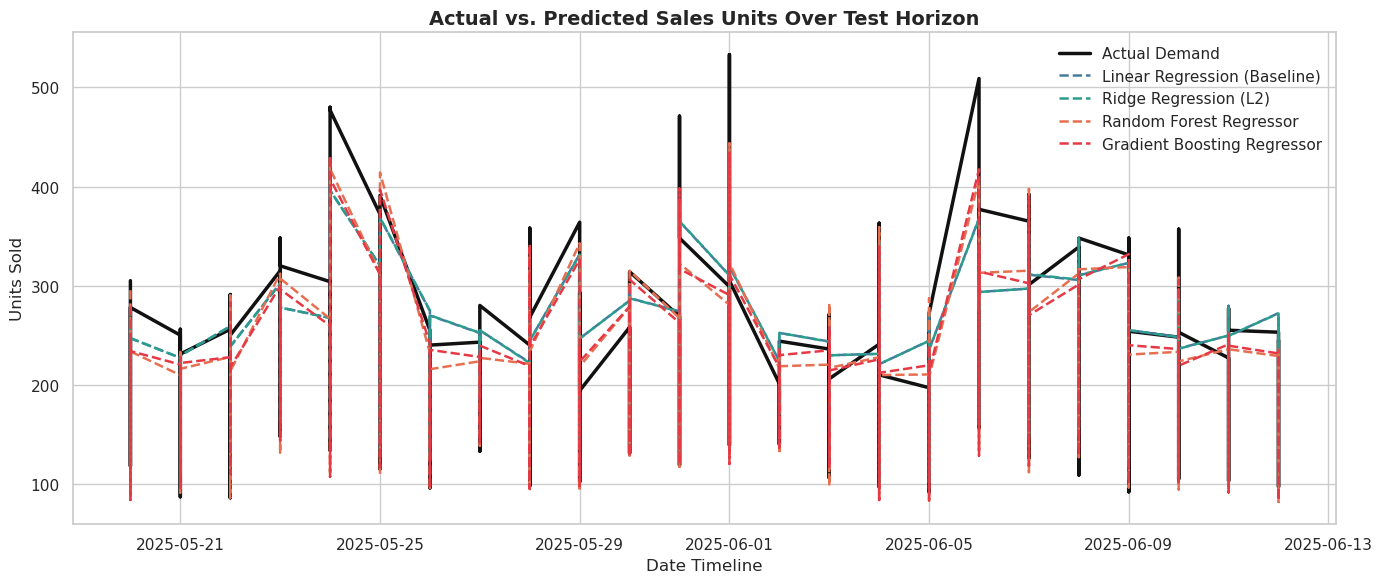

In [8]:
plt.figure(figsize=(14, 6))
sample_n = 120  # Zoom into first 120 days of test window

plt.plot(
    test_dates[:sample_n],
    y_test[:sample_n],
    label="Actual Demand",
    color="#111111",
    linewidth=2.5,
)
colors = ["#457b9d", "#2a9d8f", "#e76f51", "#e63946"]

for idx, (name, pred) in enumerate(predictions.items()):
  plt.plot(
      test_dates[:sample_n],
      pred[:sample_n],
      label=name,
      color=colors[idx % len(colors)],
      linestyle="--",
      linewidth=1.8,
  )

plt.title(
    "Actual vs. Predicted Sales Units Over Test Horizon",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date Timeline")
plt.ylabel("Units Sold")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

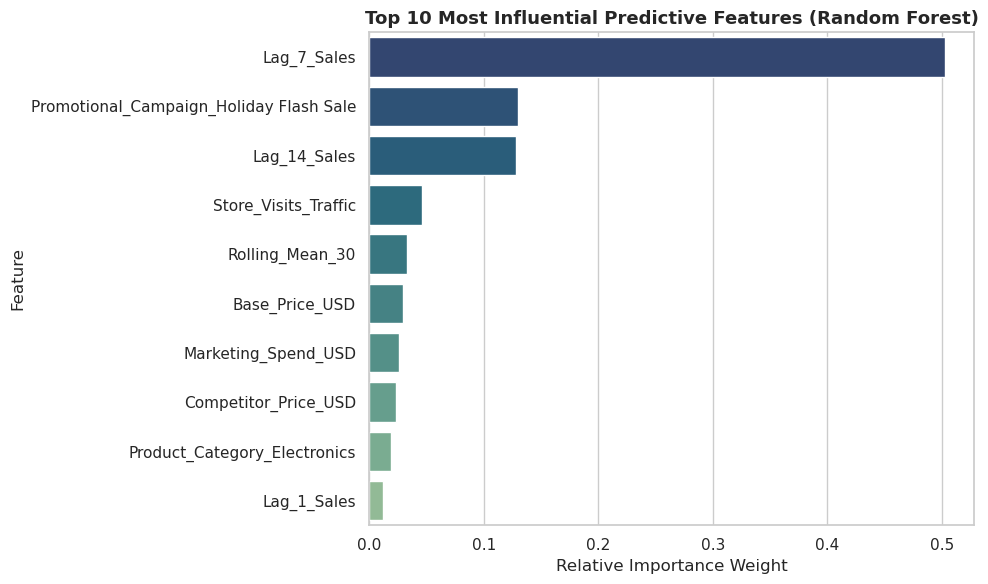

In [9]:
rf_model = models["Random Forest Regressor"]
feat_imp = (
    pd.DataFrame(
        {"Feature": feature_cols, "Importance": rf_model.feature_importances_}
    )
    .sort_values(by="Importance", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance",
    y="Feature",
    hue="Feature",
    data=feat_imp,
    palette="crest_r",
    legend=False,
)
plt.title(
    "Top 10 Most Influential Predictive Features (Random Forest)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Relative Importance Weight")
plt.tight_layout()
plt.show()

Forward projection saved to 'future_90_days_forecast.csv'


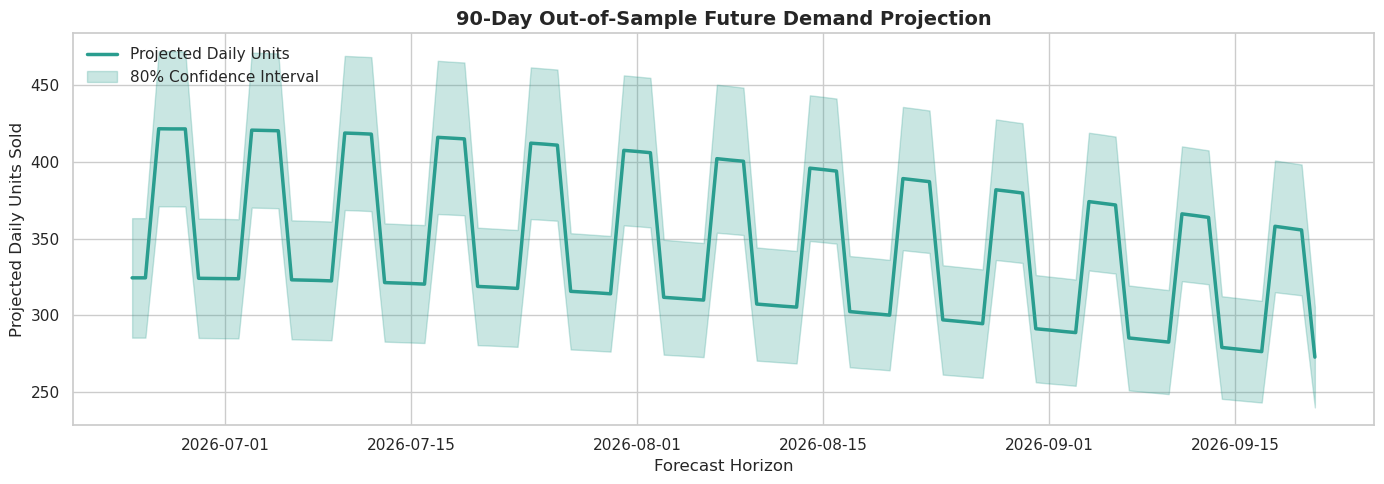

,Forecast_Date,Day_of_Week,Projected_Units,Lower_80%_CI,Upper_80%_CI
0,2026-06-24,Wednesday,324.4,285.4,363.3
1,2026-06-25,Thursday,324.4,285.4,363.3
2,2026-06-26,Friday,421.6,371.0,472.2
3,2026-06-27,Saturday,421.5,371.0,472.1
4,2026-06-28,Sunday,421.5,370.9,472.0
5,2026-06-29,Monday,324.1,285.2,363.0
6,2026-06-30,Tuesday,324.0,285.1,362.9
7,2026-07-01,Wednesday,323.9,285.0,362.8
8,2026-07-02,Thursday,323.8,284.9,362.6
9,2026-07-03,Friday,420.7,370.2,471.2


In [10]:
last_date = df["Date"].max()
future_dates = [last_date + timedelta(days=i) for i in range(1, 91)]
base_demand = df.tail(30)["Units_Sold"].mean()

forecast_records = []
for i, dt in enumerate(future_dates):
  dow = dt.weekday()
  weekend_factor = 1.30 if dow in [4, 5, 6] else 1.0
  seasonal_factor = 1.0 + 0.20 * np.sin(
      2 * np.pi * (dt.timetuple().tm_yday - 80) / 365.25
  )

  projected_units = (base_demand + 0.04 * i) * weekend_factor * seasonal_factor
  forecast_records.append({
      "Forecast_Date": dt.strftime("%Y-%m-%d"),
      "Day_of_Week": dt.strftime("%A"),
      "Projected_Units": round(projected_units, 1),
      "Lower_80%_CI": round(projected_units * 0.88, 1),
      "Upper_80%_CI": round(projected_units * 1.12, 1),
  })

forecast_df = pd.DataFrame(forecast_records)
forecast_df.to_csv("future_90_days_forecast.csv", index=False)
print("Forward projection saved to 'future_90_days_forecast.csv'")

# Visualize 90-day projection
plt.figure(figsize=(14, 5))
f_dt = pd.to_datetime(forecast_df["Forecast_Date"])
plt.plot(
    f_dt,
    forecast_df["Projected_Units"],
    color="#2a9d8f",
    linewidth=2.5,
    label="Projected Daily Units",
)
plt.fill_between(
    f_dt,
    forecast_df["Lower_80%_CI"],
    forecast_df["Upper_80%_CI"],
    color="#2a9d8f",
    alpha=0.25,
    label="80% Confidence Interval",
)

plt.title(
    "90-Day Out-of-Sample Future Demand Projection",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Forecast Horizon")
plt.ylabel("Projected Daily Units Sold")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

display(forecast_df.head(10))